# Telecom Customer Retention Analysis

**Goal:** understand which customer characteristics are associated with churn and build a baseline model that can help a telecom business identify customers who may need retention attention.

This analysis is organized around business questions rather than only model accuracy.

## 1. Business questions
1. How large is the churn problem?
2. Which customer groups show higher churn rates?
3. How do contract type, tenure, internet service and payment method relate to churn?
4. Can a simple classification model identify customers at higher churn risk?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', None)
DATA_PATH = Path('../data/telco_customer_churn.csv')
df = pd.read_csv(DATA_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data quality and preparation

In [2]:
df.shape, df.isna().sum().sort_values(ascending=False).head(10)

((7043, 21),
 customerID         0
 gender             0
 SeniorCitizen      0
 Partner            0
 Dependents         0
 tenure             0
 PhoneService       0
 MultipleLines      0
 InternetService    0
 OnlineSecurity     0
 dtype: int64)

In [3]:
df = df.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.drop(columns=['customerID'])
df['SeniorCitizen'] = df['SeniorCitizen'].map({0:'No', 1:'Yes'})
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

### Churn overview

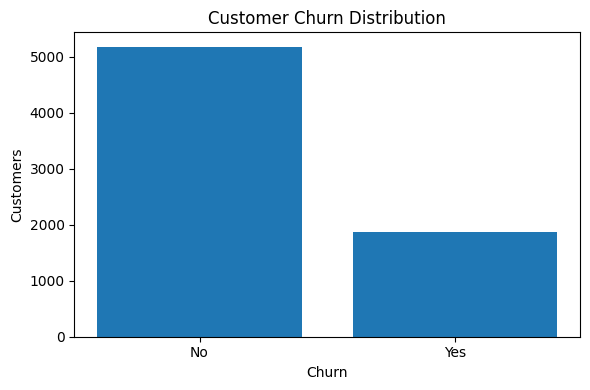

In [4]:
counts = df['Churn'].value_counts().reindex(['No','Yes'])
plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Customers')
plt.tight_layout()
plt.show()

## 3. Customer segments and churn
The following views focus on variables a retention team can act on.

In [5]:
def churn_by(column):
    out = df.groupby(column)['ChurnFlag'].agg(['count','mean']).sort_values('mean', ascending=False)
    out['churn_rate'] = out['mean'].map(lambda x: f'{x:.1%}')
    return out[['count','churn_rate']]

for col in ['Contract','InternetService','PaymentMethod','SeniorCitizen']:
    print(f'\n{col}')
    display(churn_by(col))


Contract


,count,churn_rate
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%



InternetService


,count,churn_rate
InternetService,,
Fiber optic,3096,41.9%
DSL,2421,19.0%
No,1526,7.4%



PaymentMethod


,count,churn_rate
PaymentMethod,,
Electronic check,2365,45.3%
Mailed check,1612,19.1%
Bank transfer (automatic),1544,16.7%
Credit card (automatic),1522,15.2%



SeniorCitizen


,count,churn_rate
SeniorCitizen,,
Yes,1142,41.7%
No,5901,23.6%


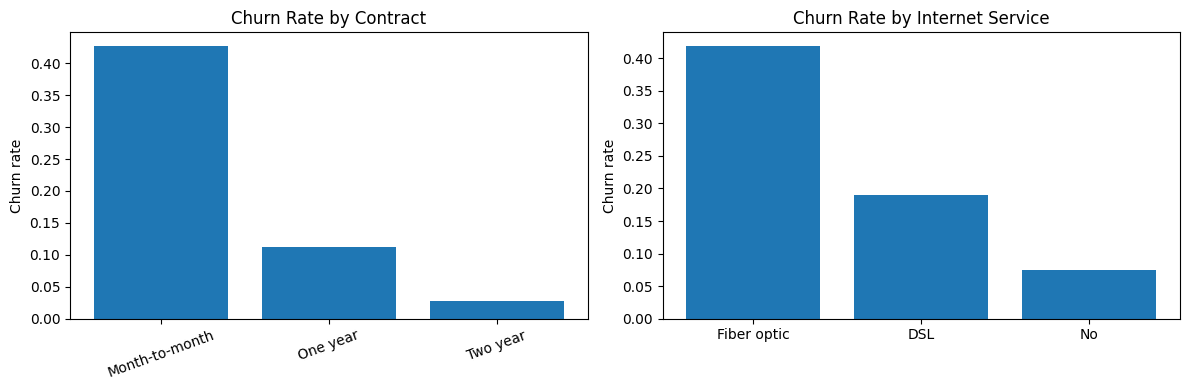

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
contract_rates = df.groupby('Contract')['ChurnFlag'].mean().sort_values(ascending=False)
axes[0].bar(contract_rates.index, contract_rates.values)
axes[0].set_title('Churn Rate by Contract')
axes[0].set_ylabel('Churn rate')
axes[0].tick_params(axis='x', rotation=20)
internet_rates = df.groupby('InternetService')['ChurnFlag'].mean().sort_values(ascending=False)
axes[1].bar(internet_rates.index, internet_rates.values)
axes[1].set_title('Churn Rate by Internet Service')
axes[1].set_ylabel('Churn rate')
plt.tight_layout()
plt.show()

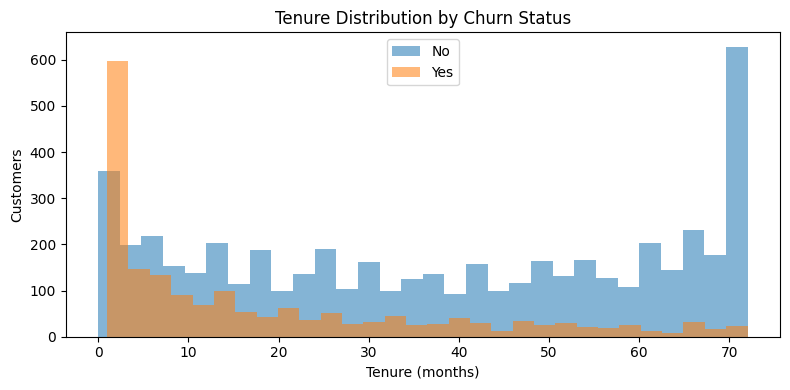

In [7]:
plt.figure(figsize=(8,4))
for label, subset in df.groupby('Churn'):
    plt.hist(subset['tenure'], bins=30, alpha=0.55, label=label)
plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Tenure (months)')
plt.ylabel('Customers')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
df.groupby('Churn')['MonthlyCharges'].agg(['count','mean','median']).round(2)

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


## 4. Modeling
A stratified train/test split is used. Categorical variables are one-hot encoded inside the pipeline to avoid preprocessing leakage.

In [9]:
X = df.drop(columns=['Churn','ChurnFlag'])
y = df['ChurnFlag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_features = X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
}

results=[]
trained={}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:,1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test,pred),
        'Precision': precision_score(y_test,pred),
        'Recall': recall_score(y_test,pred),
        'F1': f1_score(y_test,pred),
        'ROC_AUC': roc_auc_score(y_test,prob)
    })
    trained[name]=pipe

results_df = pd.DataFrame(results).sort_values('ROC_AUC', ascending=False)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.737,0.503,0.783,0.613,0.841
1,Random Forest,0.770,0.551,0.717,0.623,0.839


Selected model for inspection: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



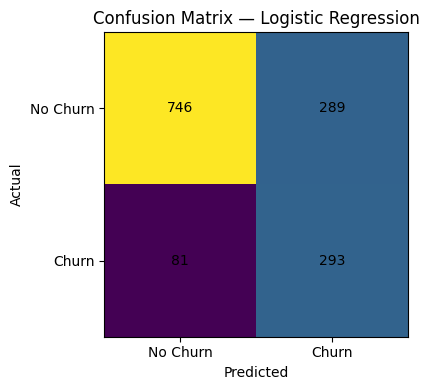

In [10]:
best_name = results_df.iloc[0]['Model']
best_model = trained[best_name]
pred = best_model.predict(X_test)
print('Selected model for inspection:', best_name)
print(classification_report(y_test, pred, target_names=['No Churn','Churn']))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5,4))
plt.imshow(cm, interpolation='nearest')
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks([0,1], ['No Churn','Churn'])
plt.yticks([0,1], ['No Churn','Churn'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha='center', va='center')
plt.tight_layout()
plt.show()

## 5. Business takeaways
- Churn should be examined by **contract, tenure, service mix and payment behavior**, not just as one overall percentage.
- Month-to-month customers generally represent an important retention segment in this dataset.
- Short-tenure customers deserve attention because early-stage customers can behave differently from long-tenure customers.
- Model performance should be interpreted using recall, precision, F1 and ROC-AUC rather than accuracy alone because churn classes are imbalanced.

> These are observations from this dataset, not universal telecom rules. A production retention program would validate them on current customer data and measure the financial impact of interventions.

## 6. Next steps
For a production version, add customer-level scoring, threshold tuning based on retention campaign capacity, model monitoring, and an interactive Power BI/Tableau dashboard.